# DS201 · Lab 2: Mạng nơ-ron tích chập (CNN) trên VinaFood21

Notebook thực hành huấn luyện và đánh giá 4 mô hình: LeNet-5, GoogLeNet, ResNet-18 và Pretrained ResNet-50.

> **Lưu ý:** Chọn **Runtime** -> **Change runtime type** -> chọn **T4 GPU** trước khi chạy.

In [1]:
# 0. Clone repo tu GitHub neu dang chay tren Colab
import os, sys

if 'google.colab' in sys.modules:
    if not os.path.exists('data.py'):
        !git clone https://github.com/Alice0602/DS201_Lab2.git /content/DS201_Lab2
        %cd /content/DS201_Lab2
    !git config --global user.name "Alice0602"
    !git config --global user.email "nguyen.phuongtuyen.1002@gmail.com"
    print('Working dir:', os.getcwd())


Cloning into '/content/DS201_Lab2'...
remote: Enumerating objects: 30, done.
remote: Counting objects: 100% (30/30), done.
remote: Compressing objects: 100% (23/23), done.
remote: Total 30 (delta 9), reused 27 (delta 7), pack-reused 0 (from 0)
Receiving objects: 100% (30/30), 360.04 KiB | 12.86 MiB/s, done.
Resolving deltas: 100% (9/9), done.
/content/DS201_Lab2
Working dir: /content/DS201_Lab2


In [2]:
# 1. Kiem tra GPU
!nvidia-smi

Wed Oct 28 14:30:20 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
# 2. Cai cac thu vien can thiet
!pip install -q -r requirements.txt

In [4]:
# 3. Tai bo du lieu VinaFood21 tu Google Drive
from data import download_vinafood21
download_vinafood21("VinaFood21")

Downloading...
From (original): https://drive.google.com/uc?id=1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR
From (redirected): https://drive.google.com/uc?id=1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR&confirm=t&uuid=9a7b9bbc-ecd6-49cd-9410-68a6cd7d4892
To: /content/DS201_Lab2/VinaFood21.zip
100%|██████████| 2.71G/2.71G [00:26<00:00, 103MB/s]


Extracting VinaFood21.zip...
Done!


## Cách 1: Chạy tự động tất cả 4 bài

In [ ]:
!python run_all.py --data_root VinaFood21

## Cách 2: Chạy từng bài riêng biệt

In [5]:
# --- Bai 1: LeNet-5 (AvgPool vs MaxPool) ---
!python train.py --model lenet_avg --epochs 20
!python evaluate.py --ckpt outputs/lenet_avg/best.pt

!python train.py --model lenet_max --epochs 20
!python evaluate.py --ckpt outputs/lenet_max/best.pt


--- Training lenet_avg | device=cuda | size=64x64 | lr=0.001 | epochs=20 ---
Model params: 339,421 (trainable: 339,421)
Epoch  1/20 | Train 2.8130/0.1431 | Val 2.5807/0.2092 F1 0.1178 | 134.3s *
Epoch  2/20 | Train 2.5787/0.2108 | Val 2.4552/0.2410 F1 0.1648 | 129.6s *
Epoch  3/20 | Train 2.4842/0.2404 | Val 2.3669/0.2729 F1 0.2056 | 132.6s *
Epoch  4/20 | Train 2.4216/0.2567 | Val 2.3208/0.2590 F1 0.2166 | 130.5s *
Epoch  5/20 | Train 2.3677/0.2675 | Val 2.2706/0.3008 F1 0.2411 | 127.1s *
Epoch  6/20 | Train 2.3162/0.2884 | Val 2.2638/0.3078 F1 0.2770 | 121.8s *
Epoch  7/20 | Train 2.2789/0.2989 | Val 2.2298/0.3157 F1 0.2754 | 125.3s
Epoch  8/20 | Train 2.2357/0.3084 | Val 2.1950/0.3277 F1 0.2787 | 126.0s *
Epoch  9/20 | Train 2.1863/0.3288 | Val 2.2115/0.3187 F1 0.2684 | 127.6s
Epoch 10/20 | Train 2.1432/0.3415 | Val 2.1828/0.3347 F1 0.2960 | 125.5s *
Epoch 11/20 | Train 2.1119/0.3491 | Val 2.1781/0.3347 F1 0.2997 | 122.2s *
Epoch 12/20 | Train 2.0791/0.3571 | Val 2.1185/0.3486 F1 0

In [6]:
# --- Bai 2: GoogLeNet (Inception blocks) ---
!python train.py --model googlenet --epochs 20
!python evaluate.py --ckpt outputs/googlenet/best.pt


--- Training googlenet | device=cuda | size=64x64 | lr=0.001 | epochs=20 ---
Model params: 332,557 (trainable: 332,557)
Epoch  1/20 | Train 2.8852/0.1132 | Val 2.6504/0.1962 F1 0.1164 | 125.2s *
Epoch  2/20 | Train 2.6447/0.1830 | Val 2.4772/0.2361 F1 0.1610 | 124.3s *
Epoch  3/20 | Train 2.4851/0.2310 | Val 2.3581/0.2709 F1 0.2071 | 125.9s *
Epoch  4/20 | Train 2.3715/0.2624 | Val 2.2227/0.2958 F1 0.2465 | 125.6s *
Epoch  5/20 | Train 2.2987/0.2884 | Val 2.1431/0.3357 F1 0.2896 | 129.0s *
Epoch  6/20 | Train 2.2290/0.3094 | Val 2.1196/0.3556 F1 0.3004 | 127.5s *
Epoch  7/20 | Train 2.1745/0.3228 | Val 2.0374/0.3884 F1 0.3284 | 127.3s *
Epoch  8/20 | Train 2.1018/0.3467 | Val 1.9954/0.3865 F1 0.3338 | 128.2s *
Epoch  9/20 | Train 2.0417/0.3676 | Val 1.9196/0.4124 F1 0.3644 | 131.1s *
Epoch 10/20 | Train 1.9941/0.3840 | Val 1.9940/0.3984 F1 0.3448 | 132.0s
Epoch 11/20 | Train 1.9522/0.3919 | Val 1.8704/0.4343 F1 0.3814 | 130.3s *
Epoch 12/20 | Train 1.9149/0.4063 | Val 1.7760/0.4482 F1

In [7]:
# --- Bai 3*: ResNet-18 (So sanh Khong Augment vs Co Augment) ---
!python train.py --model resnet18 --no_augment --epochs 20
!python evaluate.py --ckpt outputs/resnet18_noaug/best.pt

!python train.py --model resnet18 --epochs 20
!python evaluate.py --ckpt outputs/resnet18_aug/best.pt


--- Training resnet18 | device=cuda | size=96x96 | lr=0.001 | epochs=20 ---
Model params: 11,187,285 (trainable: 11,187,285)
Epoch  1/20 | Train 2.6620/0.1989 | Val 2.6054/0.2450 F1 0.1720 | 123.4s *
Epoch  2/20 | Train 2.3378/0.2801 | Val 2.2273/0.2958 F1 0.2445 | 121.6s *
Epoch  3/20 | Train 2.1421/0.3357 | Val 2.8258/0.2181 F1 0.1692 | 119.9s
Epoch  4/20 | Train 1.9640/0.3843 | Val 2.0488/0.3685 F1 0.3432 | 120.4s *
Epoch  5/20 | Train 1.8062/0.4363 | Val 1.9430/0.3984 F1 0.3600 | 120.7s *
Epoch  6/20 | Train 1.6062/0.4886 | Val 2.0217/0.3954 F1 0.3403 | 122.8s
Epoch  7/20 | Train 1.4071/0.5441 | Val 1.8995/0.4412 F1 0.4108 | 122.1s *
Epoch  8/20 | Train 1.1833/0.6199 | Val 1.8277/0.4552 F1 0.4293 | 122.1s *
Epoch  9/20 | Train 0.8760/0.7107 | Val 2.0039/0.4691 F1 0.4381 | 120.9s *
Epoch 10/20 | Train 0.5761/0.8098 | Val 2.1026/0.4532 F1 0.4398 | 121.6s *
Epoch 11/20 | Train 0.3729/0.8787 | Val 2.2845/0.4781 F1 0.4474 | 121.4s *
Epoch 12/20 | Train 0.2545/0.9140 | Val 2.5689/0.4900

In [8]:
# --- Bai 4*: Pretrained ResNet-50 (Feature Extraction vs Fine-Tuning) ---
!python train.py --model resnet50_fe --epochs 15 --lr 1e-3
!python evaluate.py --ckpt outputs/resnet50_fe/best.pt

!python train.py --model resnet50_ft --epochs 10 --lr 1e-4
!python evaluate.py --ckpt outputs/resnet50_ft/best.pt


--- Training resnet50_fe | device=cuda | size=224x224 | lr=0.001 | epochs=15 ---
config.json: 100% 69.6k/69.6k [00:00<00:00, 72.6MB/s]

model.safetensors: downloading bytes:  82% 84.1M/102M [00:01<00:00, 99.7MB/s, 7.29MB/s  ]
model.safetensors: downloading bytes: 100% 96.1M/96.1M [00:01<00:00, 61.6MB/s, 9.03MB/s  ]
model.safetensors: reconstructing file: 100% 102M/102M [00:01<00:00, 65.7MB/s, 9.87MB/s  ]
Loading weights: 100% 320/320 [00:00<00:00, 5077.20it/s]
Model params: 23,551,061 (trainable: 43,029)
Epoch  1/15 | Train 2.4481/0.3279 | Val 2.1367/0.4920 F1 0.4631 | 167.0s *
Epoch  2/15 | Train 1.8508/0.5263 | Val 1.8321/0.5538 F1 0.5477 | 167.1s *
Epoch  3/15 | Train 1.5908/0.5791 | Val 1.6180/0.5737 F1 0.5686 | 168.2s *
Epoch  4/15 | Train 1.4307/0.6094 | Val 1.5120/0.6185 F1 0.6105 | 166.7s *
Epoch  5/15 | Train 1.3220/0.6412 | Val 1.4240/0.6305 F1 0.6275 | 168.1s *
Epoch  6/15 | Train 1.2524/0.6499 | Val 1.3457/0.6434 F1 0.6424 | 173.2s *
Epoch  7/15 | Train 1.1969/0.6626 | Val

## Đồ thị & Bảng kết quả tổng hợp


Bieu do Overfitting ResNet-18:


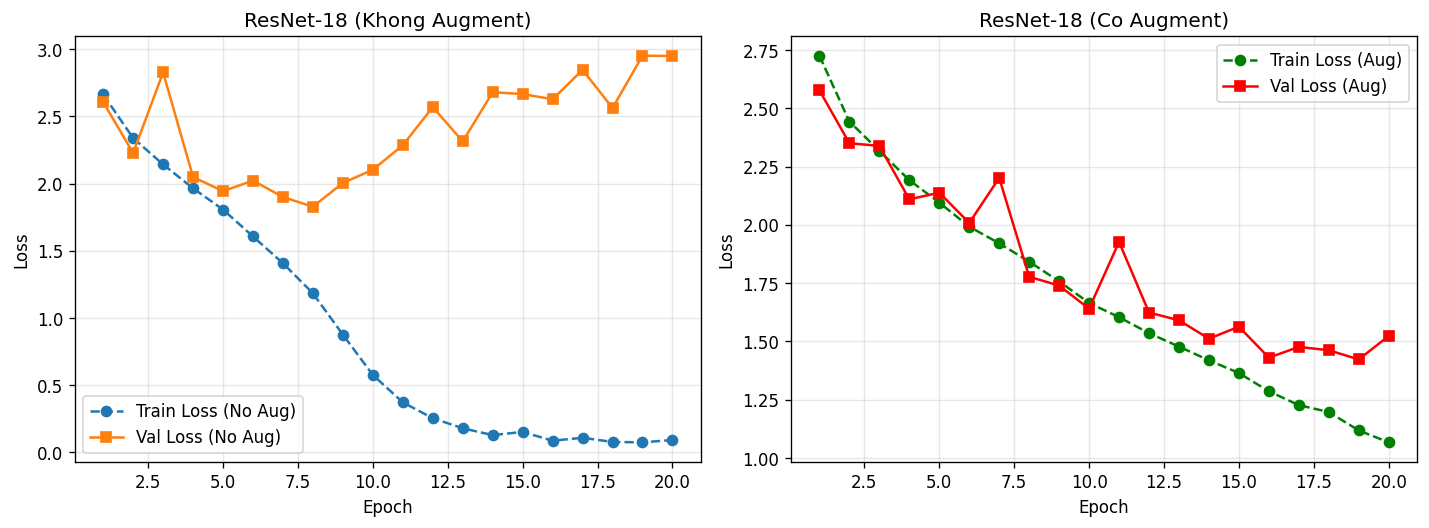


Confusion Matrix - lenet_avg:


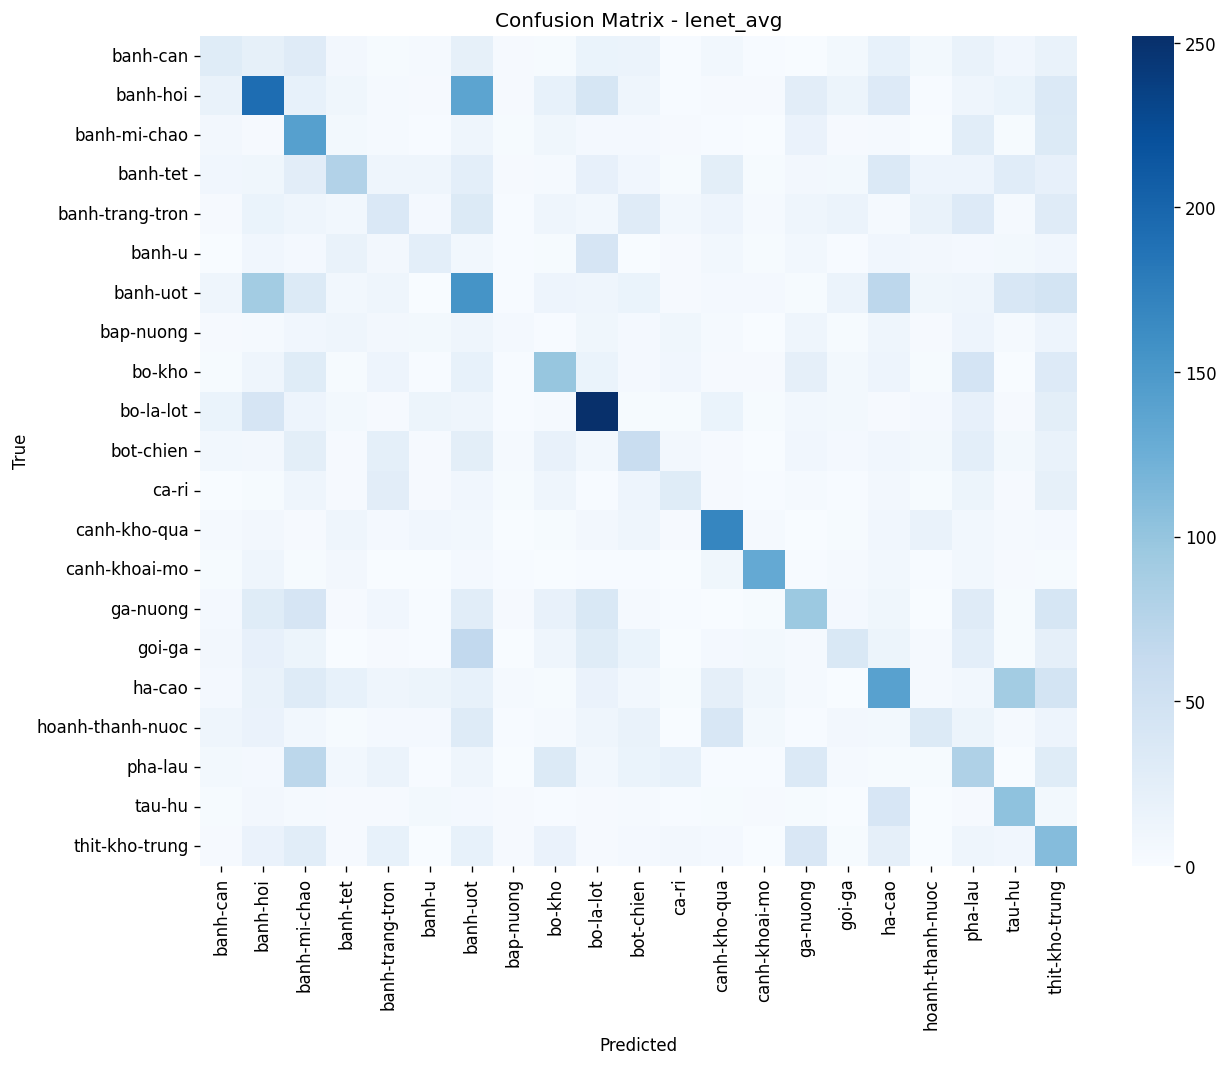


Confusion Matrix - googlenet:


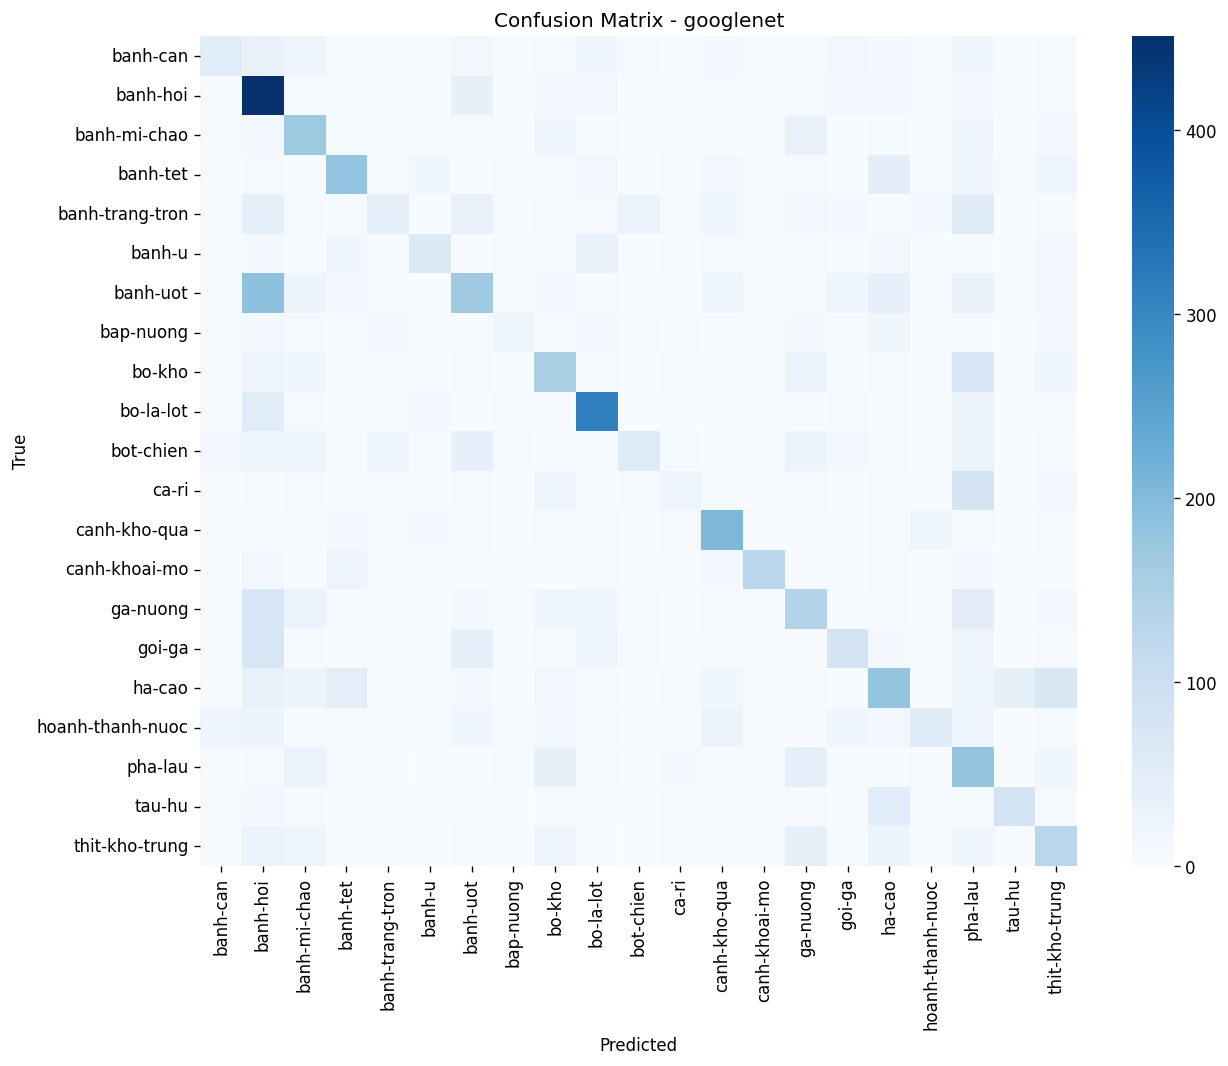


Confusion Matrix - resnet18_aug:


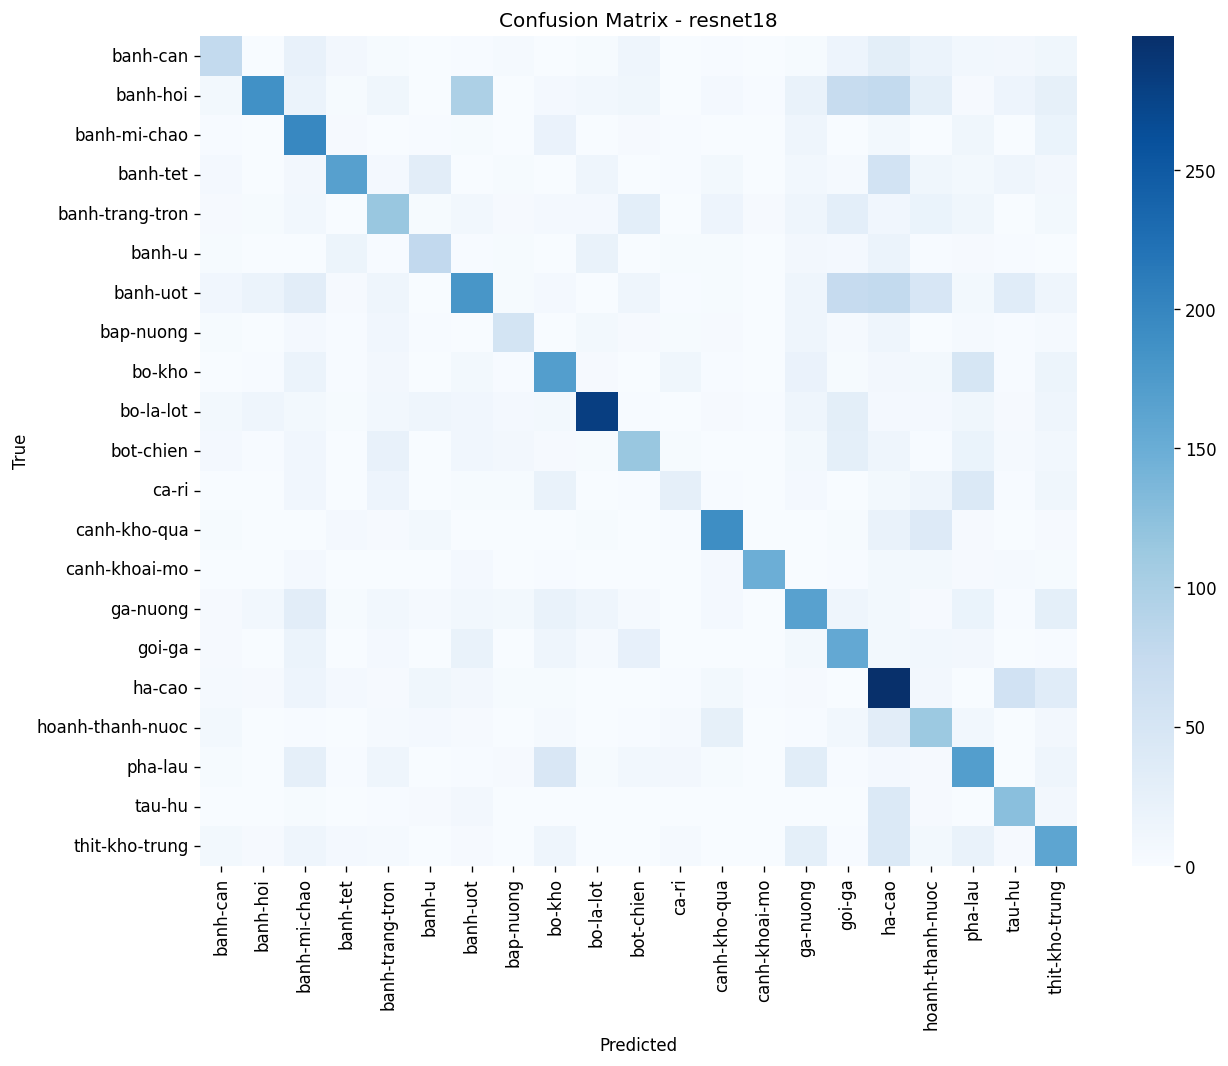


Confusion Matrix - resnet50_ft:


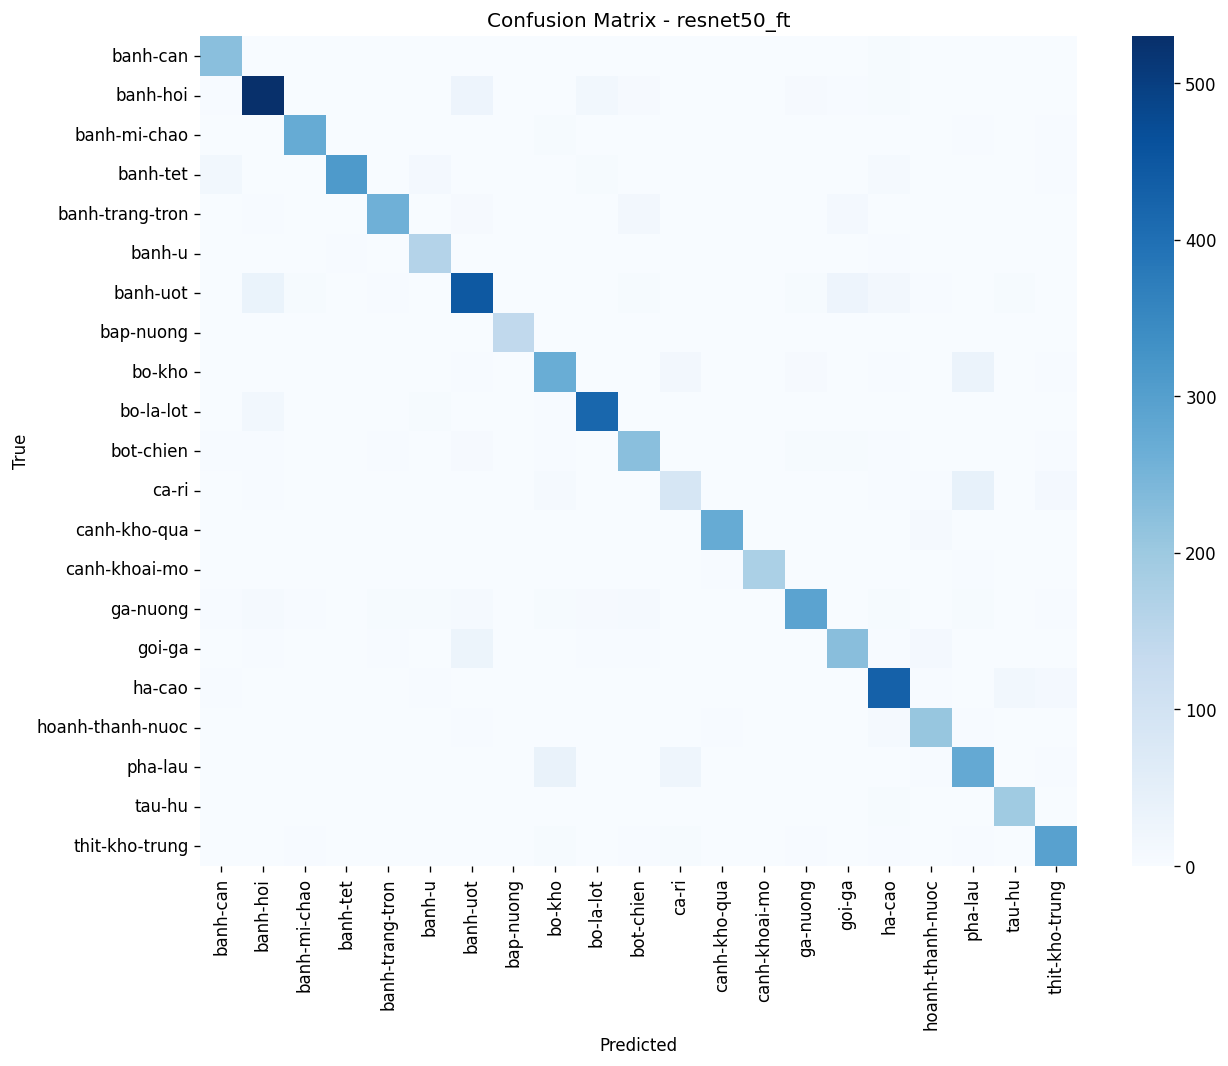

In [9]:
import pandas as pd
from IPython.display import Image, display
from pathlib import Path
from run_all import (
    plot_resnet18_comparison,
    plot_all_loss_curves,
    plot_confusion_matrices_row,
    plot_all_confusion_matrices,
)

# 1. Bang tong hop ket qua
summary_path = Path("outputs/summary_table.csv")
if summary_path.is_file():
    df = pd.read_csv(summary_path)
    print("--- Bang tong hop ket qua ---")
    display(df)

# 2. Do thi Loss (Train vs Val) cho tat ca 7 mo hinh
plot_all_loss_curves()
loss_path = Path("outputs/loss_all_models.png")
if loss_path.is_file():
    print("\nDo thi Loss (Train vs Val) cua tat ca mo hinh:")
    display(Image(str(loss_path)))

# 3. Do thi doi chieu Overfitting ResNet-18 (Bai 3*)
plot_resnet18_comparison()
cmp_path = Path("outputs/resnet18_overfitting_comparison.png")
if cmp_path.is_file():
    print("\nBieu do Overfitting ResNet-18 (Khong Aug vs Co Aug):")
    display(Image(str(cmp_path)))

# 4. Confusion Matrix (4 mo hinh dai dien tren 1 hang)
plot_confusion_matrices_row()
cm_row_path = Path("outputs/confusion_matrices_row.png")
if cm_row_path.is_file():
    print("\nConfusion Matrix (4 mo hinh dai dien tren 1 hang):")
    display(Image(str(cm_row_path)))

# 5. Confusion Matrix cho tat ca 7 mo hinh
plot_all_confusion_matrices()
cm_all_path = Path("outputs/confusion_matrices_all.png")
if cm_all_path.is_file():
    print("\nConfusion Matrix cho tat ca 7 mo hinh:")
    display(Image(str(cm_all_path)))
